## Import Libraries

In [89]:
from pathlib import Path
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder ,StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

import joblib


## Load Dataset

In [90]:
import kagglehub

path = kagglehub.dataset_download(
    "maqdadali/mental-health-risk-prediction-dataset-students"
)
print(path)

C:\Users\Youcode\.cache\kagglehub\datasets\maqdadali\mental-health-risk-prediction-dataset-students\versions\1


In [91]:
files = list(Path(path).iterdir())

print(files)

[WindowsPath('C:/Users/Youcode/.cache/kagglehub/datasets/maqdadali/mental-health-risk-prediction-dataset-students/versions/1/README.md'), WindowsPath('C:/Users/Youcode/.cache/kagglehub/datasets/maqdadali/mental-health-risk-prediction-dataset-students/versions/1/student_mental_health.csv')]


In [92]:
csv_files = list(Path(path).glob("*.csv"))

df = pd.read_csv(csv_files[0])

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [93]:
import shutil

raw_path = Path("../data/raw")
raw_path.mkdir(parents=True , exist_ok=True)

shutil.copy2(csv_files[0], raw_path / csv_files[0].name)

WindowsPath('../data/raw/student_mental_health.csv')

## Data Understanding

In [94]:
df.shape

(2000, 17)

In [95]:
df.columns.tolist()

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [96]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [97]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [98]:
df.describe(include="object")

C:\Users\Youcode\AppData\Local\Temp\ipykernel_32224\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


In [99]:
df["Mental_Health_Risk"].value_counts()

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

In [100]:
df["Mental_Health_Risk"].value_counts(normalize=True) * 100

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

In [101]:
df["Mental_Health_Risk"].dtype

<StringDtype(na_value=nan)>

## Data Quality Audit

In [102]:
df.isnull().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [103]:
df.duplicated().sum()

np.int64(0)

## Data Consistency & Outliers

In [104]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [105]:
columns = df.select_dtypes(include="number").columns

for col in columns:
    Q1= df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[ (df[col] < lower) | (df[col] > upper) ]

    print(col , ":", len(outliers))


Age : 4
Year_of_Study : 0
Sleep_Hours : 2
Study_Hours_Per_Week : 7
GPA : 9
Social_Media_Hours : 20
Screen_Time_Hours : 7
Financial_Stress : 0
Family_Support : 0
Attendance_Rate : 12


## Outlier Visualization

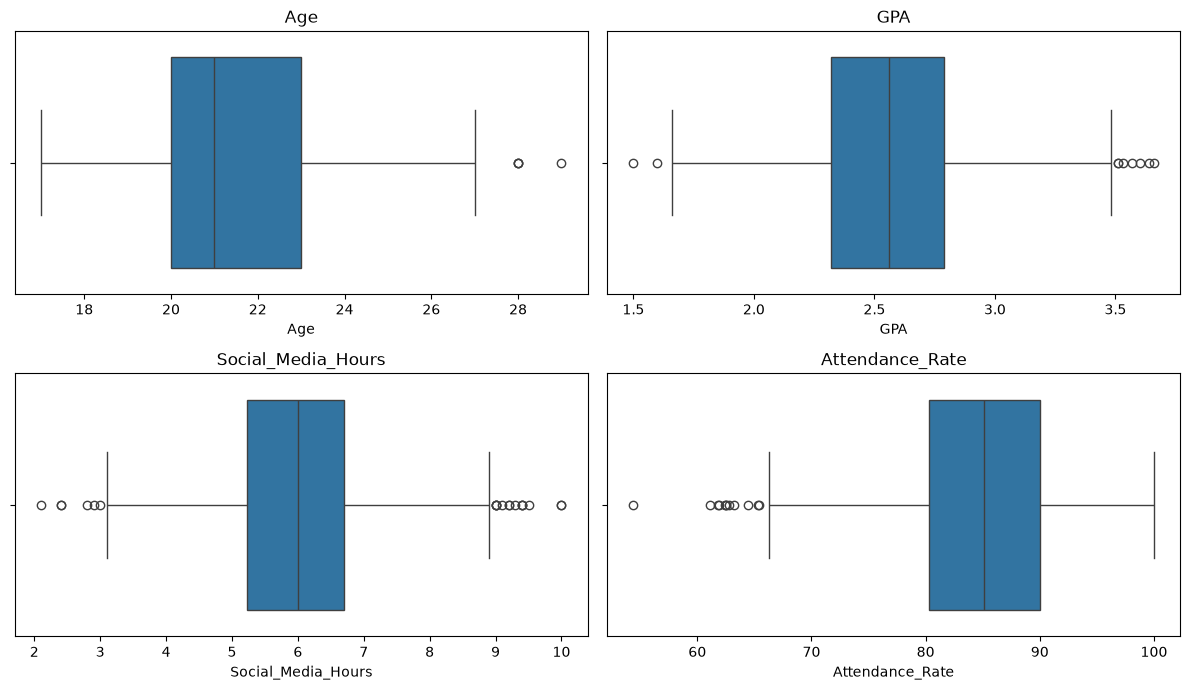

In [106]:
columns = ["Age", "GPA", "Social_Media_Hours", "Attendance_Rate"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for col, ax in zip(columns, axes.flat):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


## Categorical Data Consistency

In [107]:
categorical_cols = df.select_dtypes(include=["object", "string"]).columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


Student_ID
Student_ID
STU0001    1
STU0002    1
STU0003    1
STU0004    1
STU0005    1
          ..
STU1996    1
STU1997    1
STU1998    1
STU1999    1
STU2000    1
Name: count, Length: 2000, dtype: int64

Gender
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

Previous_Mental_Health_History
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


## Categorical Distribution

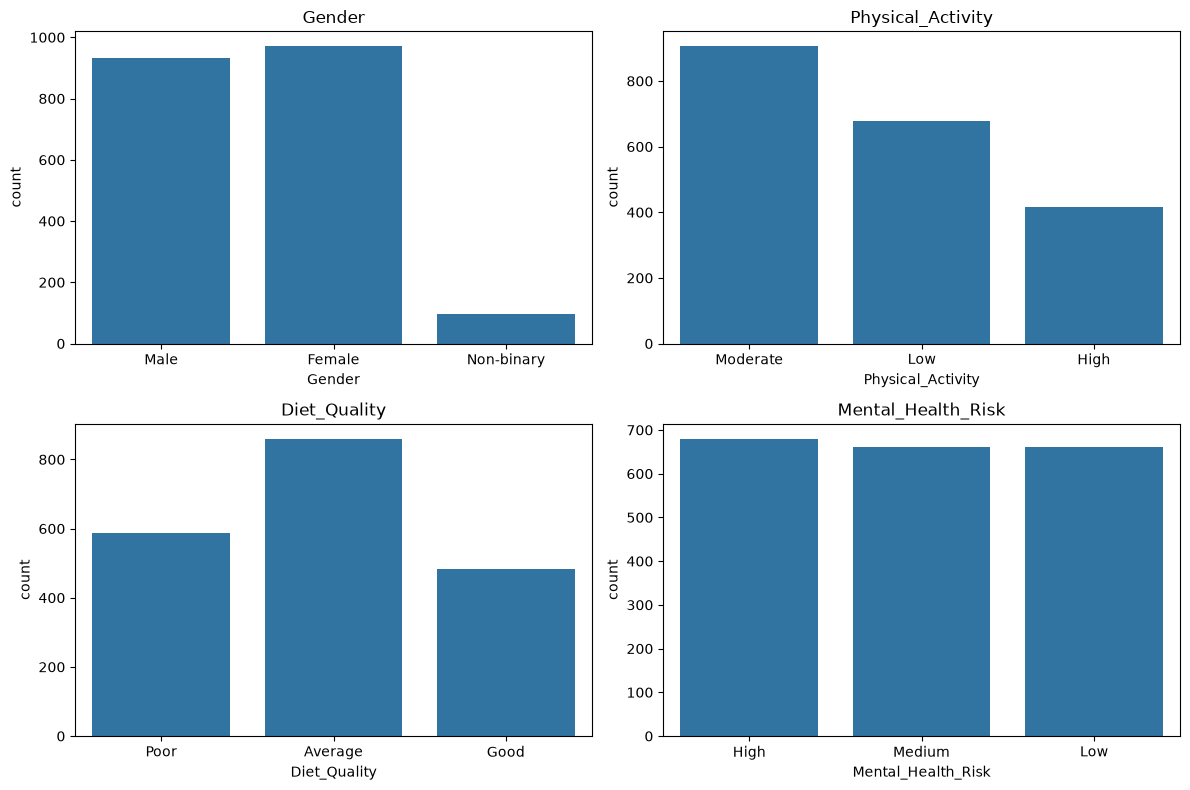

In [108]:
columns = ["Gender", "Physical_Activity", "Diet_Quality", "Mental_Health_Risk"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(columns, axes.flat):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## Numerical Distribution

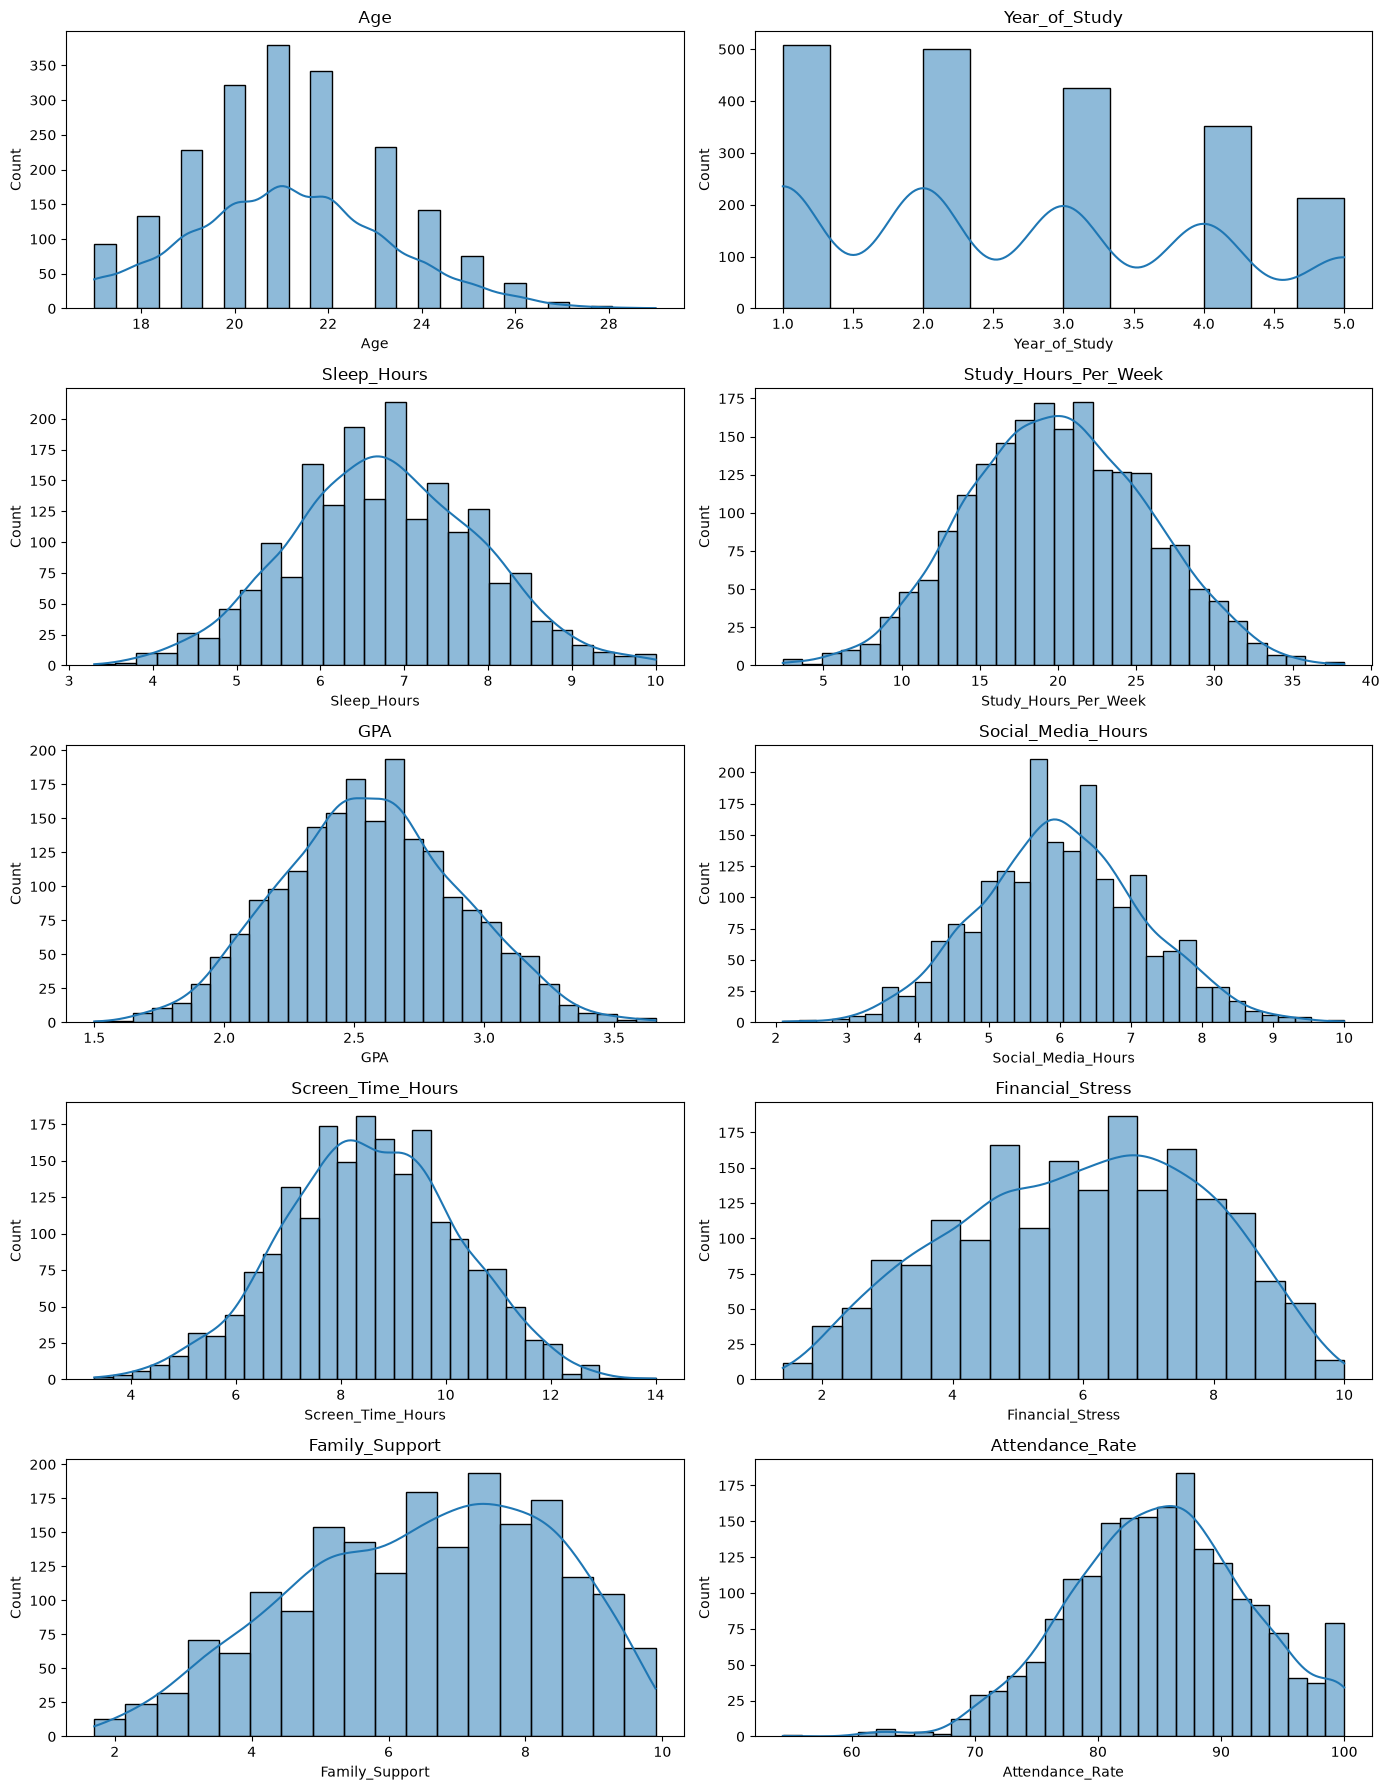

In [109]:
numerical_cols = df.select_dtypes(include="number").columns

fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for col, ax in zip(numerical_cols, axes.flat):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## Bivariate Analysis

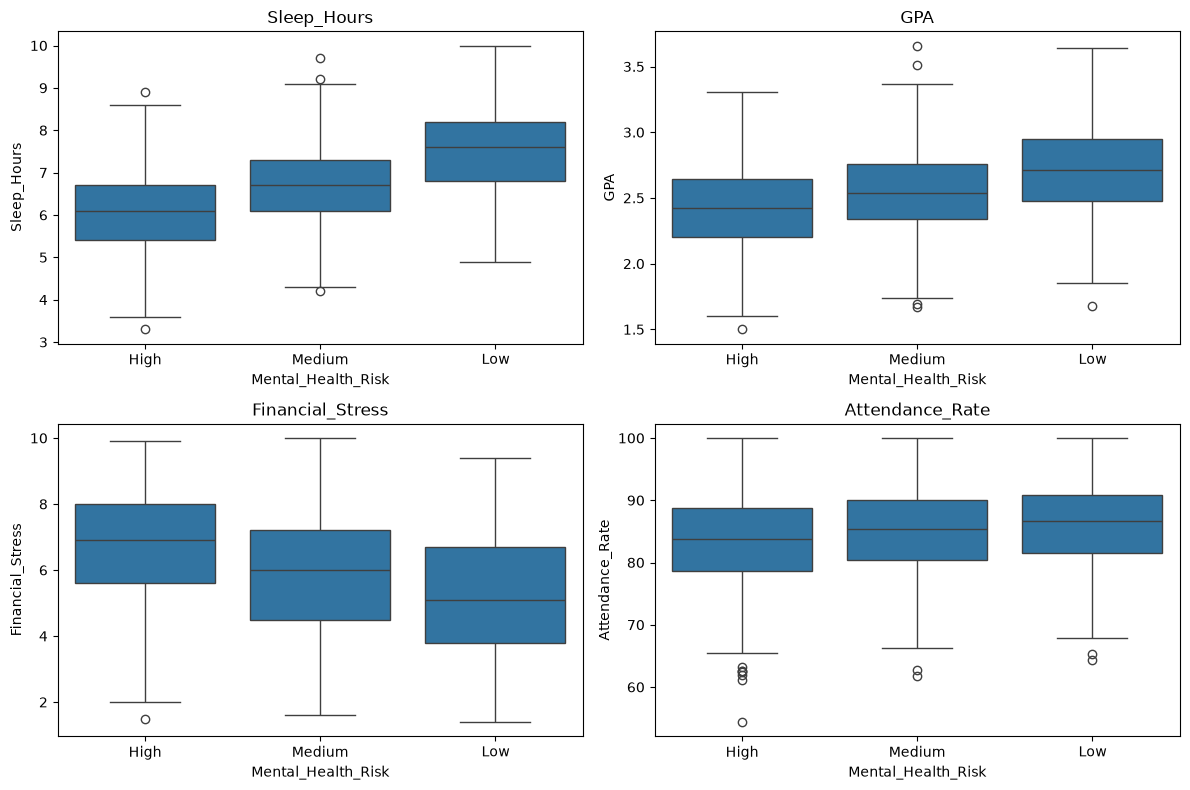

In [110]:
columns = ["Sleep_Hours", "GPA", "Financial_Stress", "Attendance_Rate"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(columns, axes.flat):
    sns.boxplot(data=df, x="Mental_Health_Risk", y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

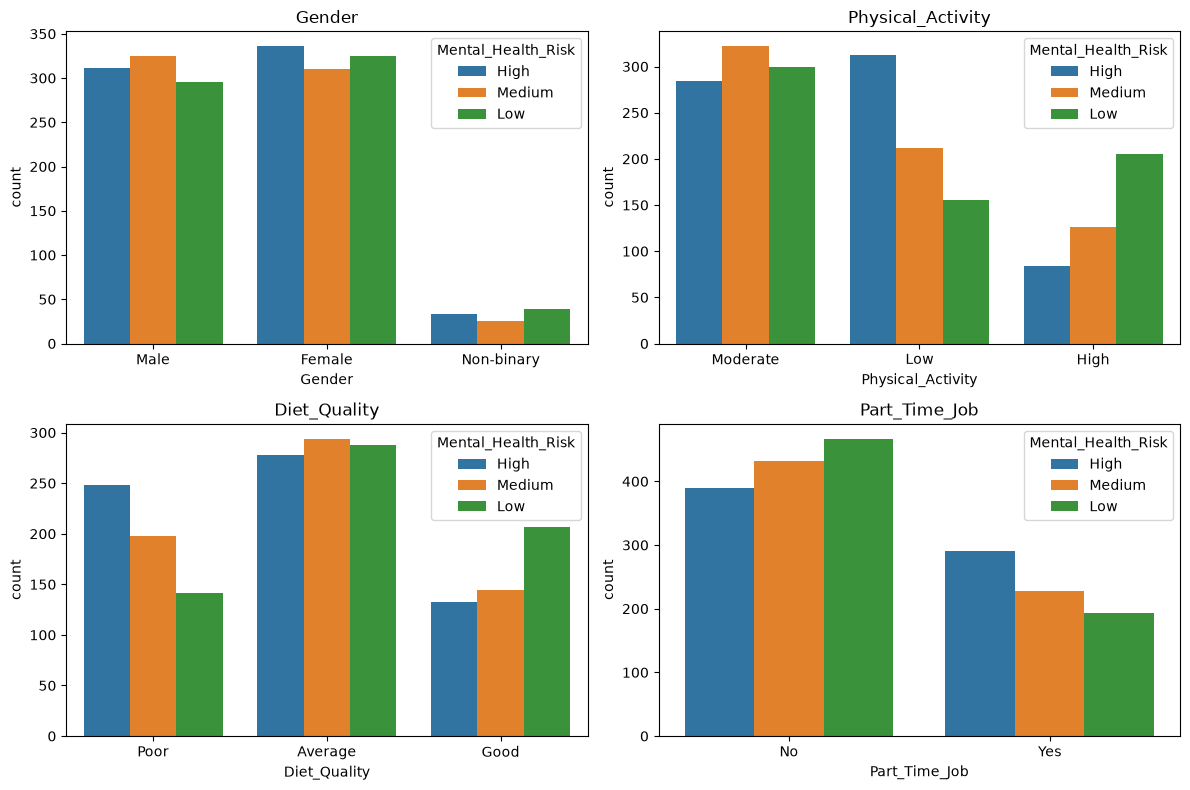

In [111]:
columns = ["Gender", "Physical_Activity", "Diet_Quality", "Part_Time_Job"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(columns, axes.flat):
    sns.countplot(data=df, x=col, hue="Mental_Health_Risk", ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## Correlation Analysis

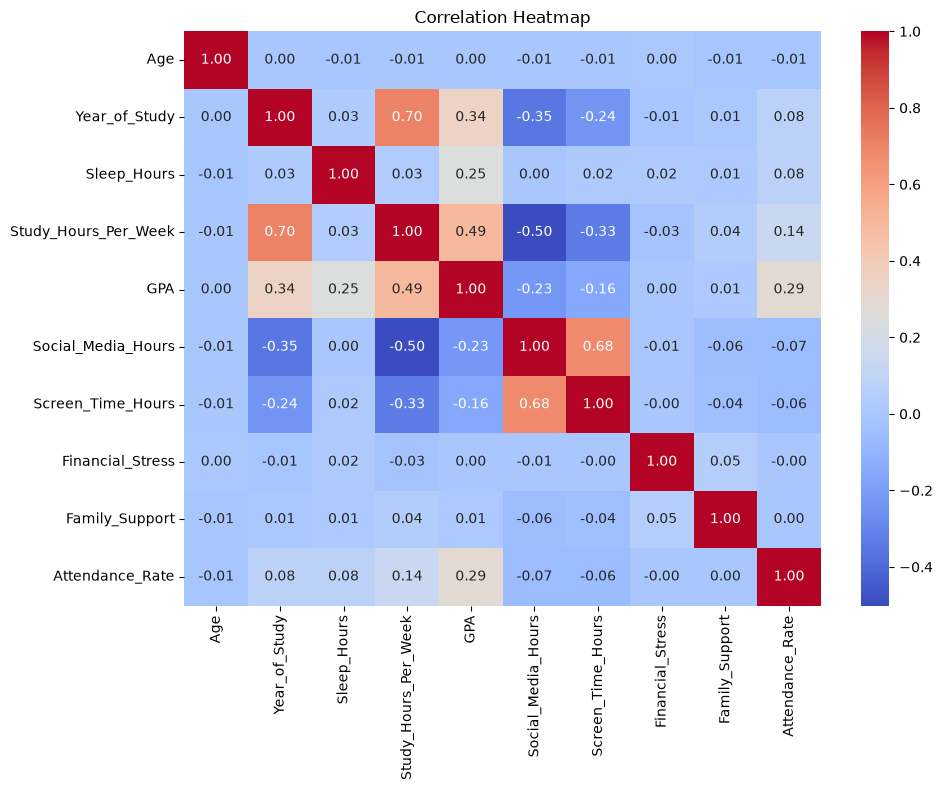

In [112]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    numerical_cols_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [113]:
corr_matrix = df.select_dtypes(include="number").corr()

pairs = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

pairs.stack().sort_values(key=abs, ascending=False).head(10)

Year_of_Study         Study_Hours_Per_Week    0.703401
Social_Media_Hours    Screen_Time_Hours       0.681404
Study_Hours_Per_Week  Social_Media_Hours     -0.501178
                      GPA                     0.492501
Year_of_Study         Social_Media_Hours     -0.353989
                      GPA                     0.344012
Study_Hours_Per_Week  Screen_Time_Hours      -0.333568
GPA                   Attendance_Rate         0.285952
Sleep_Hours           GPA                     0.246255
Year_of_Study         Screen_Time_Hours      -0.239093
dtype: float64

In [114]:
(df["Social_Media_Hours"] > df["Screen_Time_Hours"]).sum()

np.int64(37)

In [115]:
invalid_rows = (
    df["Social_Media_Hours"].notna() &
    (df["Social_Media_Hours"] > df["Screen_Time_Hours"])
)

print("Invalid rows:", invalid_rows.sum())

df = df.loc[~invalid_rows].copy()

print("Dataset shape:", df.shape)

Invalid rows: 37
Dataset shape: (1963, 17)


## Train Test Split

In [116]:
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(1570, 15)
(393, 15)


## Preprocessing Pipeline

In [117]:
numerical_features = X.select_dtypes(include="number").columns

nominal_features = [
    "Gender",
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]

ordinal_features = [
    "Physical_Activity",
    "Diet_Quality"
]

In [118]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

nominal_pipeline = Pipeline([
    ("imputer" , SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder" , OrdinalEncoder (
        categories = [
            ["Low", "Moderate" , "High"],
            ["Poor", "Average" , "Good"]
        ],
        handle_unknown = "use_encoded_value",
        unknown_value = -1
    ))
])

In [119]:
preprocessor = ColumnTransformer([
    ("num" , numerical_pipeline , numerical_features),
    ("nom", nominal_pipeline, nominal_features),
    ("ord", ordinal_pipeline, ordinal_features)

])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [120]:
from sklearn.base import clone

preprocessor_check = clone(preprocessor)

X_train_processed = preprocessor_check.fit_transform(X_train)

print("Before preprocessing:", X_train.shape)
print("After preprocessing:", X_train_processed.shape)

Before preprocessing: (1570, 15)
After preprocessing: (1570, 19)


In [121]:
model_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

## Cross Validation

In [138]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [139]:
scores = cross_val_score(
    model_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("F1 Scores:", scores)
print("Mean F1:", scores.mean())

F1 Scores: [0.72634642 0.74608875 0.77138537 0.78110445 0.76132756]
Mean F1: 0.7572505108987729


In [157]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Best Parameters: {'model__C': 10}
Best CV F1: 0.7578546034477622


## Random Forest Baseline

In [141]:
rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

In [142]:
rf_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("F1 Scores:", rf_scores)
print("Mean F1:", rf_scores.mean())
print("Standard Deviation:", rf_scores.std())

F1 Scores: [0.67183229 0.64127933 0.64504599 0.6993882  0.67328332]
Mean F1: 0.6661658266524253
Standard Deviation: 0.021222057414296117


## Random Forest Hyperparameter Tuning

In [143]:
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

rf_grid_search.fit(X_train, y_train)

print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV F1:", rf_grid_search.best_score_)

Best Parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV F1: 0.6872587962298223


## XGBoost Target Encoding

In [144]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

In [145]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)

print(dict(enumerate(label_encoder.classes_)))

{0: 'High', 1: 'Low', 2: 'Medium'}


In [146]:
xgb_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

In [147]:
xgb_scores = cross_val_score(
    xgb_pipeline,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring="f1_macro"
)

print("F1 Scores:", xgb_scores)
print("Mean F1:", xgb_scores.mean())
print("Standard Deviation:", xgb_scores.std())

F1 Scores: [0.68206573 0.69675752 0.6468691  0.73955745 0.69955061]
Mean F1: 0.6929600819023957
Standard Deviation: 0.029907307534231233


In [148]:
xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0]
}

xgb_grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

xgb_grid_search.fit(X_train, y_train_encoded)

print("Best Parameters:", xgb_grid_search.best_params_)
print("Best CV F1:", xgb_grid_search.best_score_)

Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best CV F1: 0.7051908064311416


In [169]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "CV F1 Macro": [
        grid_search.best_score_,
        rf_grid_search.best_score_,
        xgb_grid_search.best_score_
    ]
})

results = results.sort_values(
    by="CV F1 Macro",
    ascending=False
)

results

,Model,CV F1 Macro
0,Logistic Regression,0.757855
2,XGBoost,0.705191
1,Random Forest,0.687259


## Final Model Evaluation

In [150]:
best_lr_model = grid_search.best_estimator_

best_rf_model = rf_grid_search.best_estimator_

best_xgb_model = xgb_grid_search.best_estimator_

In [151]:
lr_predictions = best_lr_model.predict(X_test)

rf_predictions = best_rf_model.predict(X_test)

xgb_predictions_encoded = best_xgb_model.predict(X_test)

xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded.astype(int)
)

In [152]:
models = {
    "Logistic Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro"),
        "Recall": recall_score(y_test, predictions, average="macro"),
        "F1 Score": f1_score(y_test, predictions, average="macro")
    })

test_results = pd.DataFrame(results)

test_results.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.745547,0.749761,0.744935,0.746848
2,XGBoost,0.730280,0.728660,0.729697,0.728944
1,Random Forest,0.684478,0.678981,0.683305,0.680773


In [153]:
for name, predictions in models.items():
    print("\n", name)
    print(classification_report(y_test, predictions))


 Logistic Regression
              precision    recall  f1-score   support

        High       0.82      0.78      0.80       134
         Low       0.82      0.79      0.80       130
      Medium       0.61      0.66      0.63       129

    accuracy                           0.75       393
   macro avg       0.75      0.74      0.75       393
weighted avg       0.75      0.75      0.75       393


 Random Forest
              precision    recall  f1-score   support

        High       0.73      0.75      0.74       134
         Low       0.77      0.79      0.78       130
      Medium       0.54      0.50      0.52       129

    accuracy                           0.68       393
   macro avg       0.68      0.68      0.68       393
weighted avg       0.68      0.68      0.68       393


 XGBoost
              precision    recall  f1-score   support

        High       0.78      0.75      0.77       134
         Low       0.80      0.84      0.82       130
      Medium       0.60    

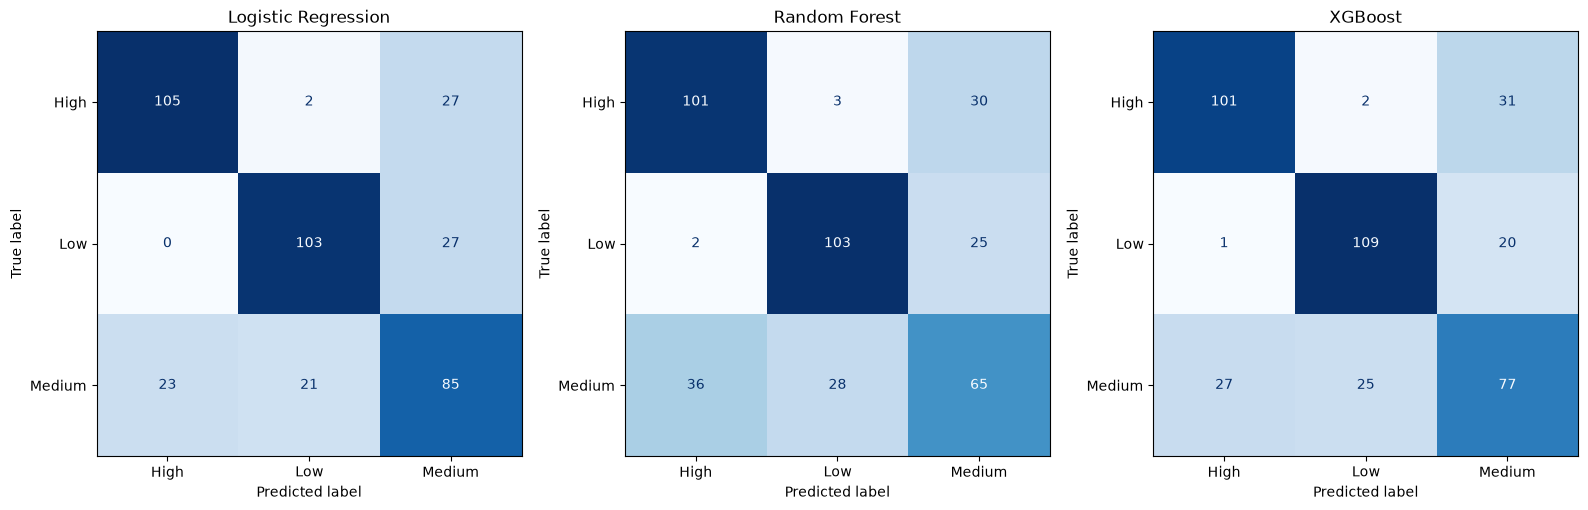

In [154]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for (name, predictions), ax in zip(models.items(), axes.flat):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=label_encoder.classes_,
        display_labels=label_encoder.classes_,
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

## Multiclass ROC-AUC Evaluation

In [158]:
from sklearn.metrics import roc_auc_score

models = {
    "Logistic Regression": best_lr_model,
    "Random Forest": best_rf_model,
    "XGBoost": best_xgb_model
}

for name, model in models.items():
    probabilities = model.predict_proba(X_test)

    auc = roc_auc_score(
        y_test,
        probabilities,
        labels=["High", "Low", "Medium"],
        multi_class="ovr",
        average="macro"
    )

    print(name, "ROC-AUC:", round(auc, 4))

Logistic Regression ROC-AUC: 0.9047
Random Forest ROC-AUC: 0.8627
XGBoost ROC-AUC: 0.8832


## ROC-AUC Per Class

In [159]:
from sklearn.metrics import roc_auc_score

probabilities = best_lr_model.predict_proba(X_test)

for i, class_name in enumerate(best_lr_model.classes_):
    y_binary = (y_test == class_name).astype(int)

    auc = roc_auc_score(
        y_binary,
        probabilities[:, i]
    )

    print(class_name, "ROC-AUC:", round(auc, 4))

High ROC-AUC: 0.9384
Low ROC-AUC: 0.9554
Medium ROC-AUC: 0.8204


## Save Best Model

In [161]:
best_lr_pipeline = grid_search.best_estimator_

joblib.dump(
    best_lr_pipeline,
    "../models/logistic_regression.joblib"
)

['../models/logistic_regression.joblib']

## Export Performance Graph Data

In [163]:
import json
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

best_lr_model = grid_search.best_estimator_

joblib.dump(
    best_lr_model,
    model_dir / "logistic_regression.joblib"
)

lr_predictions = best_lr_model.predict(X_test)

metrics = {
    "accuracy": float(accuracy_score(y_test, lr_predictions)),
    "precision": float(precision_score(y_test, lr_predictions, average="macro")),
    "recall": float(recall_score(y_test, lr_predictions, average="macro")),
    "f1_macro": float(f1_score(y_test, lr_predictions, average="macro")),
    "labels": ["High", "Low", "Medium"],
    "confusion_matrix": confusion_matrix(
        y_test,
        lr_predictions,
        labels=["High", "Low", "Medium"]
    ).tolist()
}

with open(model_dir / "metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

print("Model and metrics saved successfully")

Model and metrics saved successfully


In [167]:
import json
from sklearn.metrics import roc_curve, roc_auc_score, classification_report

best_lr_model = grid_search.best_estimator_

lr_predictions = best_lr_model.predict(X_test)
lr_probabilities = best_lr_model.predict_proba(X_test)

classes = best_lr_model.classes_

report = classification_report(
    y_test,
    lr_predictions,
    output_dict=True
)

roc_data = {}

for i, class_name in enumerate(classes):
    y_binary = (y_test == class_name).astype(int)

    fpr, tpr, thresholds = roc_curve(
        y_binary,
        lr_probabilities[:, i]
    )

    auc = roc_auc_score(
        y_binary,
        lr_probabilities[:, i]
    )

    roc_data[class_name] = {
        "fpr": fpr.tolist(),
        "tpr": tpr.tolist(),
        "auc": float(auc)
    }

metrics_path = Path("../models/metrics.json")

with open(metrics_path, "r") as file:
    metrics = json.load(file)

metrics["classification_report"] = report
metrics["roc_curves"] = roc_data

with open(metrics_path, "w") as file:
    json.dump(metrics, file, indent=4)

print("Graph data saved successfully")

Graph data saved successfully
